# Workshop 1 - Supervised Learning
## Team 7 - Recommender Systems: Collaborative Filtering and Personalization
### W1 Implementation: Supervised Matrix Factorization

**Dataset:** MovieLens `ml-32m` (32,000,204 ratings, 87,585 movies, 200,948 users, 1995-2023).

EDA on the full dataset; modeling on a reproducible user subsample. Fixed seeds for reproducibility.

## 0. Configuration and Reproducibility

- Single seed and dataset paths (detects local / Colab).
- `ratings.csv` uses ~1 GB in RAM: EDA uses the full 32M rows; modeling uses a user subsample (`N_USERS_SAMPLE`) to train in minutes.

In [1]:
# === Standard workshop libraries ===
import os
import gc
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === Reproducibility: single seed for the entire notebook ===
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# === Plot styling ===
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("Global seed set to SEED =", SEED)

pandas : 3.1.0
numpy  : 2.5.4
Semilla global fijada en SEED = 42


In [3]:
# === Automatic dataset path resolution (local Windows or Colab) ===
CANDIDATE_PATHS = [
    Path(r"C:\Users\andre\OneDrive\Documentos\TranajosML\Workshop1\dataSet"),  # local machine
    Path("dataSet"),                                                            # relative path
    Path("../dataSet"),                                                         # from notebooks/
]

DATA_DIR = next((p for p in CANDIDATE_PATHS if (p / "ratings.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "'ratings.csv' not found. Update CANDIDATE_PATHS with the correct path to your dataSet."
    )

RATINGS_CSV = DATA_DIR / "ratings.csv"
MOVIES_CSV  = DATA_DIR / "movies.csv"
TAGS_CSV    = DATA_DIR / "tags.csv"
LINKS_CSV   = DATA_DIR / "links.csv"

print("Dataset at:", DATA_DIR)
for f in [RATINGS_CSV, MOVIES_CSV, TAGS_CSV, LINKS_CSV]:
    print(f"  {f.name:12s} -> {f.stat().st_size/1e6:8.1f} MB")

Dataset en: C:\Users\andre\OneDrive\Documentos\TranajosML\Workshop1\dataSet
  ratings.csv  ->    877.1 MB
  movies.csv   ->      4.2 MB
  tags.csv     ->     72.4 MB
  links.csv    ->      2.0 MB


In [4]:
# === Scale and data preparation hyperparameters ===

# Subsample size for MODELING (number of randomly sampled users).
N_USERS_SAMPLE       = 15_000   # factorization (fits comfortably in 16 GB RAM)
N_USERS_SAMPLE_TREES = 6_000    # tree/GBM baselines

# Density filters (mitigate cold-start and long-tail noise).
MIN_RATINGS_PER_USER = 10  
MIN_RATINGS_PER_ITEM = 10   

# Threshold for the CLASSIFICATION variant (like / no-like).
LIKE_THRESHOLD = 4.0        

# Top-N ranking: default K for Precision@K, Recall@K, NDCG@K, MAP@K, HitRate@K.
TOP_K = 10

# Temporal splits (fractions of the time axis).
TEST_FRACTION = 0.10        # most recent 10% -> test
VAL_FRACTION  = 0.10        # next 10%        -> validation

# Compact dtypes to keep RAM usage low
RATINGS_DTYPES = {
    "userId":    "int32",
    "movieId":   "int32",
    "rating":    "float32",
    "timestamp": "int64",
}

print("Scale configuration ready.")
print(f"  N_USERS_SAMPLE       = {N_USERS_SAMPLE:,}")
print(f"  MIN_RATINGS_PER_USER = {MIN_RATINGS_PER_USER}")
print(f"  MIN_RATINGS_PER_ITEM = {MIN_RATINGS_PER_ITEM}")
print(f"  LIKE_THRESHOLD       = {LIKE_THRESHOLD}")

Configuración de escala lista.
  N_USERS_SAMPLE       = 15,000
  MIN_RATINGS_PER_USER = 10
  MIN_RATINGS_PER_ITEM = 10
  LIKE_THRESHOLD       = 4.0


## 1. Problem Statement

Recommendation as supervised learning: the label is the observed `rating`.

| Formulation | Target | Task | Metrics |
|---|---|---|---|
| Rating prediction | `rating` 0.5-5.0 | Regression | RMSE, MAE |
| Like / no-like | `like = 1 if rating >= 4.0` | Top-N ranking | P@K, R@K, NDCG@K, MAP@K, HitRate@K |

**Why matrix factorization:** the user-item matrix (200,948 x 87,585) is >99.8% empty. MF compresses that matrix into `k` latent factors and predicts `r_hat_ui = mu + b_u + b_i + p_u . q_i`, generalizing to unobserved pairs. It is the standard benchmark in recommendation.

## 2. Data Loading and Exploration (EDA)

Dimensions, nulls/duplicates, rating distribution, long tail, sparsity, genres, years, and temporal drift. EDA uses the full 32M rows.

### 2.1 Loading

`ratings.csv` is read with compact dtypes (`int32`/`float32`) to reduce memory usage.

In [5]:
t0 = time.time()

ratings = pd.read_csv(RATINGS_CSV, dtype=RATINGS_DTYPES)
movies  = pd.read_csv(MOVIES_CSV,  dtype={"movieId": "int32"})
links   = pd.read_csv(LINKS_CSV)
tags    = pd.read_csv(TAGS_CSV, dtype={"userId": "int32", "movieId": "int32"})

print("ratings:", ratings.shape)
print("movies :", movies.shape)
print("tags   :", tags.shape)
print("links  :", links.shape)
print("\nRatings memory: {:.0f} MB".format(ratings.memory_usage(deep=True).sum()/1e6))
display(ratings.head())

ratings: (32000204, 4)
movies : (87585, 3)
tags   : (2000072, 4)
links  : (87585, 3)

Memoria ratings: 640 MB


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
# Convert timestamp (UTC seconds since 1970) to datetime:
# used for temporal analysis and chronological train/val/test splitting.
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings["year"]  = ratings["datetime"].dt.year.astype("int16")
ratings["month"] = ratings["datetime"].dt.month.astype("int8")

print("Rating time range:")
print("  from:", ratings["datetime"].min())
print("  to  :", ratings["datetime"].max())

Rango temporal de los ratings:
  desde: 1995-01-09 11:46:44
  hasta: 2023-10-13 02:29:07


### 2.2 Dimensions, Types, Nulls, and Duplicates

In [7]:
print("=== ratings.info() ===")
ratings.info(show_counts=True)

print("\n=== Nulls per column ===")
print(ratings.isnull().sum())

# A (userId, movieId) pair should be unique: each user rates a movie once.
dup = ratings.duplicated(subset=["userId", "movieId"]).sum()
print(f"\nDuplicate (userId, movieId) pairs: {dup:,}")

n_users  = ratings["userId"].nunique()
n_items  = ratings["movieId"].nunique()
n_obs    = len(ratings)
print(f"\nUnique users : {n_users:,}")
print(f"Unique movies: {n_items:,}")
print(f"Total ratings: {n_obs:,}")

=== ratings.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 7 columns):
 #   Column     Non-Null Count     Dtype         
---  ------     --------------     -----         
 0   userId     32000204 non-null  int32         
 1   movieId    32000204 non-null  int32         
 2   rating     32000204 non-null  float32       
 3   timestamp  32000204 non-null  int64         
 4   datetime   32000204 non-null  datetime64[us]
 5   year       32000204 non-null  int16         
 6   month      32000204 non-null  int8          
dtypes: datetime64[us](1), float32(1), int16(1), int32(2), int64(1), int8(1)
memory usage: 946.1 MB

=== Nulos por columna ===
userId       0
movieId      0
rating       0
timestamp    0
datetime     0
year         0
month        0
dtype: int64

Pares (userId, movieId) duplicados: 0

Usuarios únicos : 200,948
Películas únicas: 84,432
Ratings totales : 32,000,204


### 2.3 Rating Distribution

Distribution across the 0.5-5.0 scale; highlights positivity bias and the like threshold.

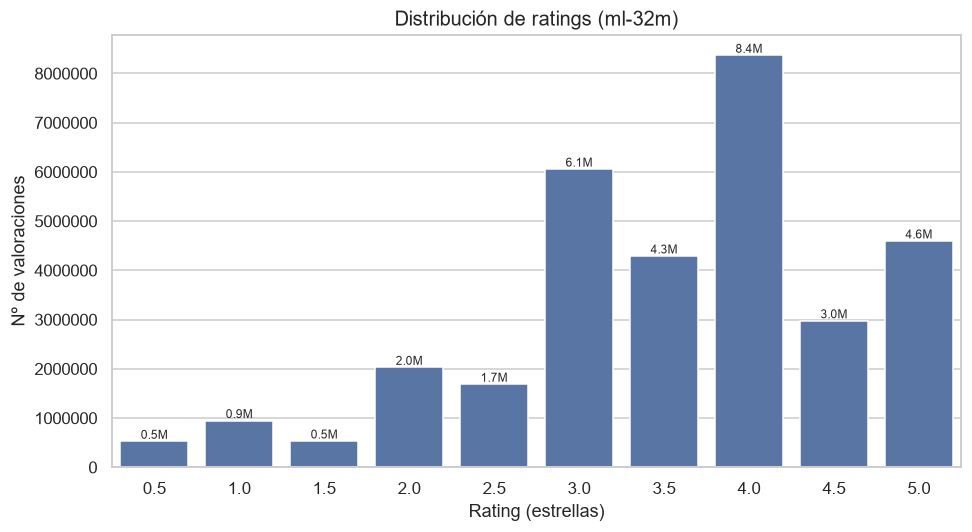

Media global de rating: 3.5404
Mediana: 3.5
% de ratings >= 4.0 (like): 49.8%


In [8]:
rating_counts = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots()
sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values,
            color="#4C72B0", ax=ax)
ax.set_title("Rating Distribution (ml-32m)")
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of ratings")
ax.ticklabel_format(style="plain", axis="y")
for i, v in enumerate(rating_counts.values):
    ax.text(i, v, f"{v/1e6:.1f}M", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

print("Global mean rating:", round(ratings['rating'].mean(), 4))
print("Median:", ratings['rating'].median())
pct_like = (ratings['rating'] >= LIKE_THRESHOLD).mean()*100
print(f"% of ratings >= {LIKE_THRESHOLD} (like): {pct_like:.1f}%")

The distribution is skewed toward high values: ratings of 3.0, 4.0, and 5.0 dominate, with far fewer very low ratings. This indicates a *positivity bias*: users mostly rate movies they chose to watch. Half-star ratings (0.5, 1.5, ...) are less frequent than whole-star ratings. This bias justifies including a **global mean μ** term in the model and explains why a *like* threshold at 4.0 yields a substantial positive fraction.

### 2.4 User Activity and Movie Popularity (Long Tail)

We expect a power law: a few users/movies accumulate most interactions.

In [9]:
ratings_per_user = ratings.groupby("userId").size()
ratings_per_item = ratings.groupby("movieId").size()

print("Ratings per USER:")
display(ratings_per_user.describe(percentiles=[.25, .5, .75, .9, .99]))
print("\nRatings per MOVIE:")
display(ratings_per_item.describe(percentiles=[.25, .5, .75, .9, .99]))

Ratings por USUARIO:


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
90%         364.000000
99%        1290.000000
max       33332.000000
dtype: float64


Ratings por PELÍCULA:


count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
90%         248.900000
99%        9263.140000
max      102929.000000
dtype: float64

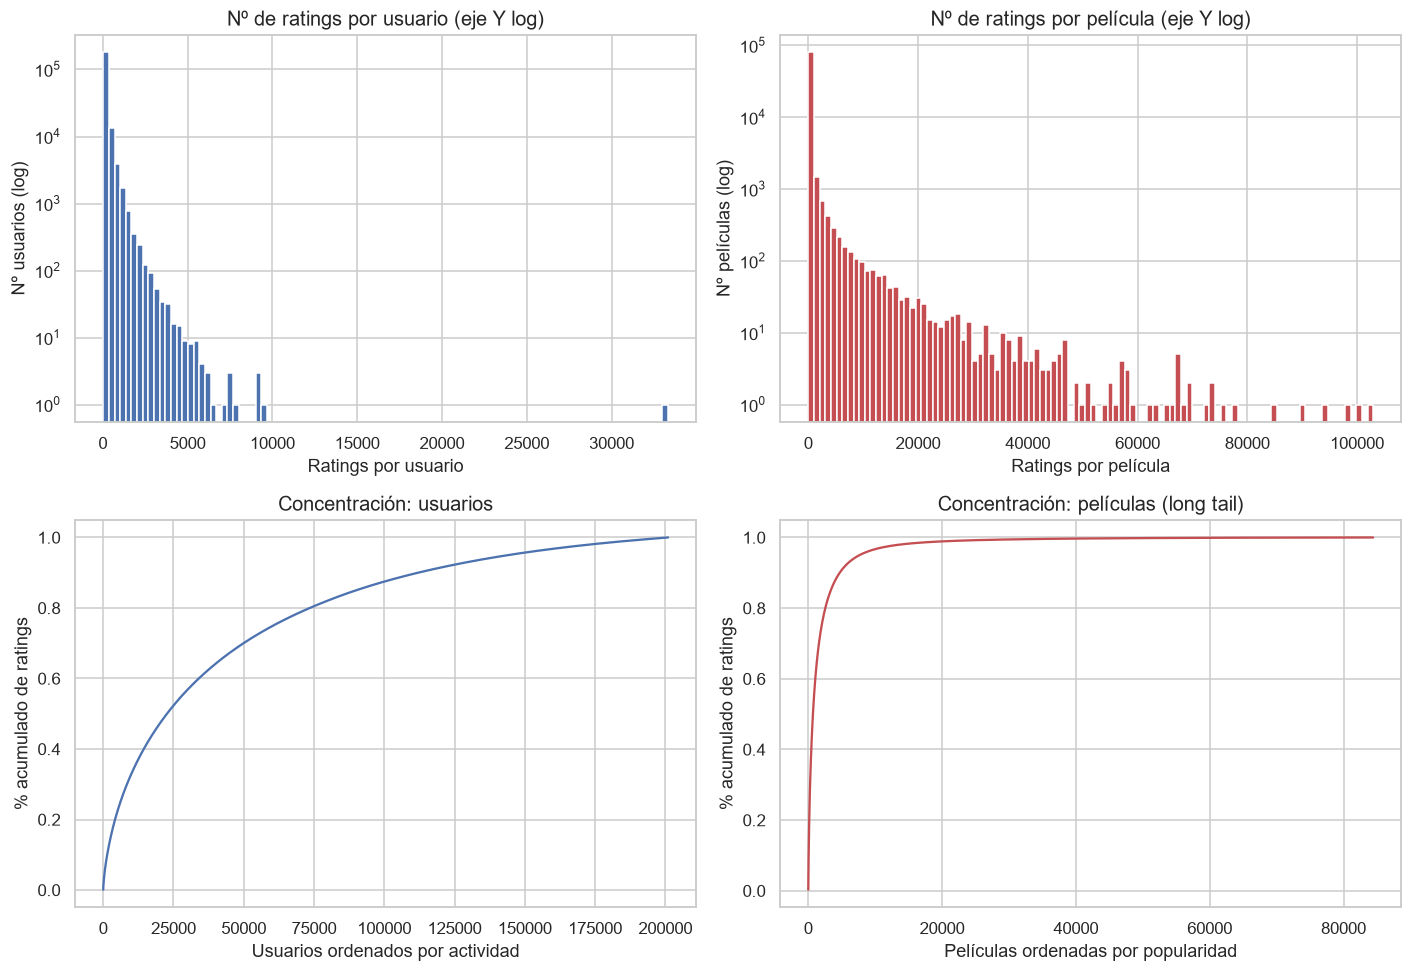

El 1% de películas más populares concentra el 54.8% de todos los ratings.


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Histograms on log-Y scale.
axes[0, 0].hist(ratings_per_user, bins=100, color="#4C72B0")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Ratings per user (log Y)")
axes[0, 0].set_xlabel("Ratings per user"); axes[0, 0].set_ylabel("Number of users (log)")

axes[0, 1].hist(ratings_per_item, bins=100, color="#C44E52")
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Ratings per movie (log Y)")
axes[0, 1].set_xlabel("Ratings per movie"); axes[0, 1].set_ylabel("Number of movies (log)")

# Concentration curves: cumulative % of ratings vs. sorted users/items.
item_sorted = np.sort(ratings_per_item.values)[::-1]
user_sorted = np.sort(ratings_per_user.values)[::-1]
axes[1, 0].plot(np.cumsum(user_sorted)/user_sorted.sum(), color="#4C72B0")
axes[1, 0].set_title("Concentration: users")
axes[1, 0].set_xlabel("Users sorted by activity")
axes[1, 0].set_ylabel("Cumulative % of ratings")
axes[1, 1].plot(np.cumsum(item_sorted)/item_sorted.sum(), color="#C44E52")
axes[1, 1].set_title("Concentration: movies (long tail)")
axes[1, 1].set_xlabel("Movies sorted by popularity")
axes[1, 1].set_ylabel("Cumulative % of ratings")

plt.tight_layout(); plt.show()

# Quantify concentration (Pareto-like rule).
top1pct_items = int(0.01 * len(item_sorted))
share = item_sorted[:top1pct_items].sum() / item_sorted.sum() * 100
print(f"The top 1% most popular movies account for {share:.1f}% of all ratings.")

Both distributions are heavily skewed (log Y scale). A handful of highly active users and *blockbusters* accumulate most interactions, while a long tail of titles has very few ratings. The concentration curves show how steep this distribution is.

Practical consequence: long-tail items will suffer from **cold-start** and unreliable predictions, justifying (a) an **item bias** term, (b) minimum-support filtering, and (c) measuring coverage and novelty during evaluation.

### 2.5 User-Item Matrix Sparsity

In [11]:
total_cells = n_users * n_items
density  = n_obs / total_cells
sparsity = 1 - density

print(f"Users × Movies = {n_users:,} × {n_items:,} = {total_cells:,} cells")
print(f"Observed ratings = {n_obs:,}")
print(f"Density  = {density*100:.4f}%")
print(f"Sparsity = {sparsity*100:.4f}%")

Usuarios × Películas = 200,948 × 84,432 = 16,966,441,536 celdas
Ratings observados   = 32,000,204
Densidad  = 0.1886%
Sparsity  = 99.8114%


The matrix is over 99.8% sparse: almost all user-movie combinations never occur. Filling those gaps with simple heuristics does not work; a model is needed to infer preferences from shared patterns. This is the exact use case for **matrix factorization**.

### 2.6 Genres

Catalog by genre and average rating by genre (over a sample of ratings).

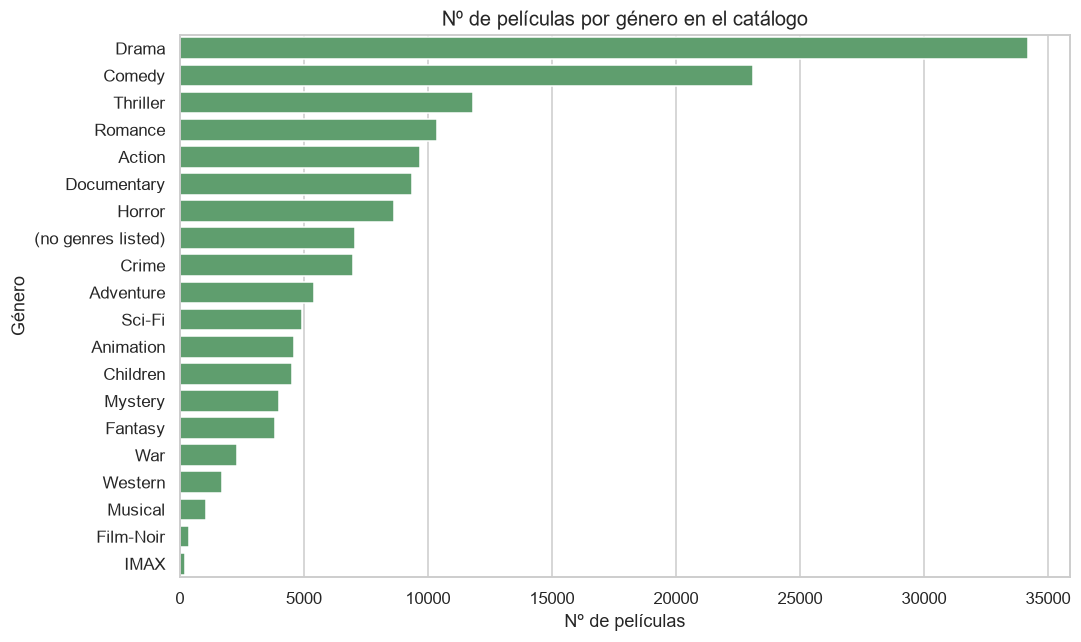

genres_list
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Name: count, dtype: int64

In [12]:
# Extract release year from title: 'Toy Story (1995)' -> 1995 using Regex
movies["year_movie"] = movies["title"].str.extract(r"\((\d{4})\)").astype("float")
movies["genres_list"] = movies["genres"].str.split("|")

genres_exploded = movies.explode("genres_list")
genre_catalog_counts = genres_exploded["genres_list"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(y=genre_catalog_counts.index, x=genre_catalog_counts.values,
            color="#55A868", ax=ax)
ax.set_title("Number of movies per genre in catalog")
ax.set_xlabel("Number of movies"); ax.set_ylabel("Genre")
plt.tight_layout(); plt.show()

display(genre_catalog_counts.head(10))

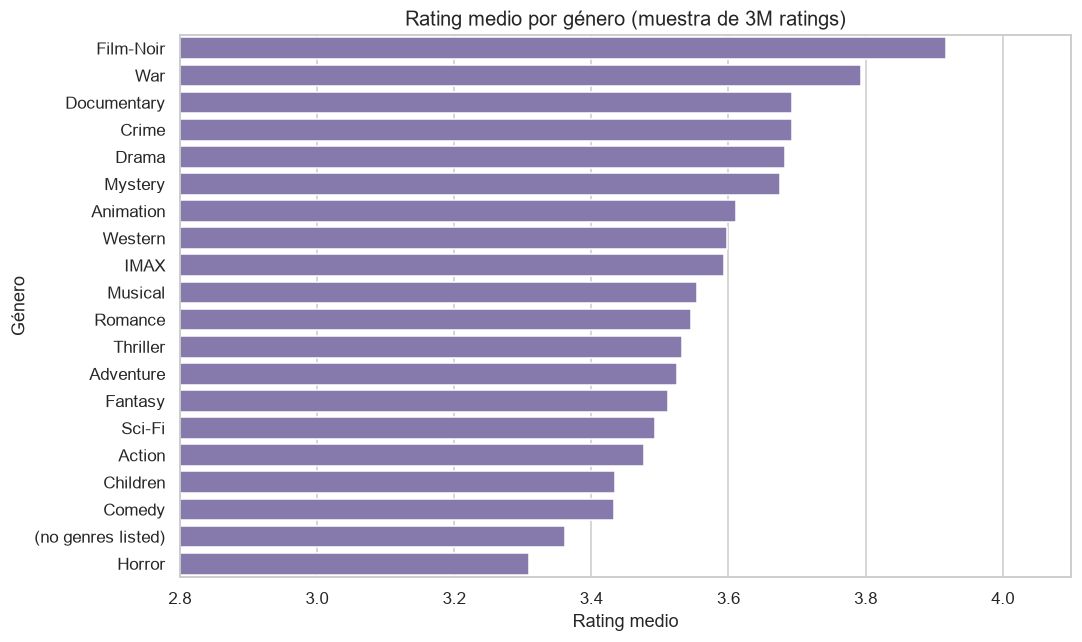

,mean,count
genres_list,,
Film-Noir,3.917,28332
War,3.794,149022
Documentary,3.693,40194
Crime,3.692,504455
Drama,3.682,1309995
Mystery,3.675,245349
Animation,3.611,207222
Western,3.598,55938
IMAX,3.594,140085


In [13]:
# Average rating per genre: join a SAMPLE of ratings with genres.
sample_for_genre = ratings.sample(n=min(3_000_000, len(ratings)), random_state=SEED)
merged = sample_for_genre.merge(movies[["movieId", "genres_list"]], on="movieId", how="left")
genre_ratings = merged.explode("genres_list")

genre_mean = (genre_ratings.groupby("genres_list")["rating"]
              .agg(["mean", "count"]).sort_values("mean", ascending=False))
genre_mean = genre_mean[genre_mean["count"] > 1000]  # avoid marginal genres

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(y=genre_mean.index, x=genre_mean["mean"], color="#8172B3", ax=ax)
ax.set_xlim(2.8, 4.1)
ax.set_title("Average rating per genre (3M ratings sample)")
ax.set_xlabel("Average rating"); ax.set_ylabel("Genre")
plt.tight_layout(); plt.show()

display(genre_mean.round(3))

The catalog is dominated by *Drama* and *Comedy* (the largest genres). In terms of average rating, genres such as *Film-Noir*, *War*, or *Documentary* tend to score slightly higher — more 'niche' works sought out by interested viewers — while mainstream genres like *Horror* or *Comedy* score lower. The difference across genres is moderate (~3.0–3.9 band), showing that genre alone explains little: per-user latent signals are needed.

### 2.7 Years and Temporal Evolution

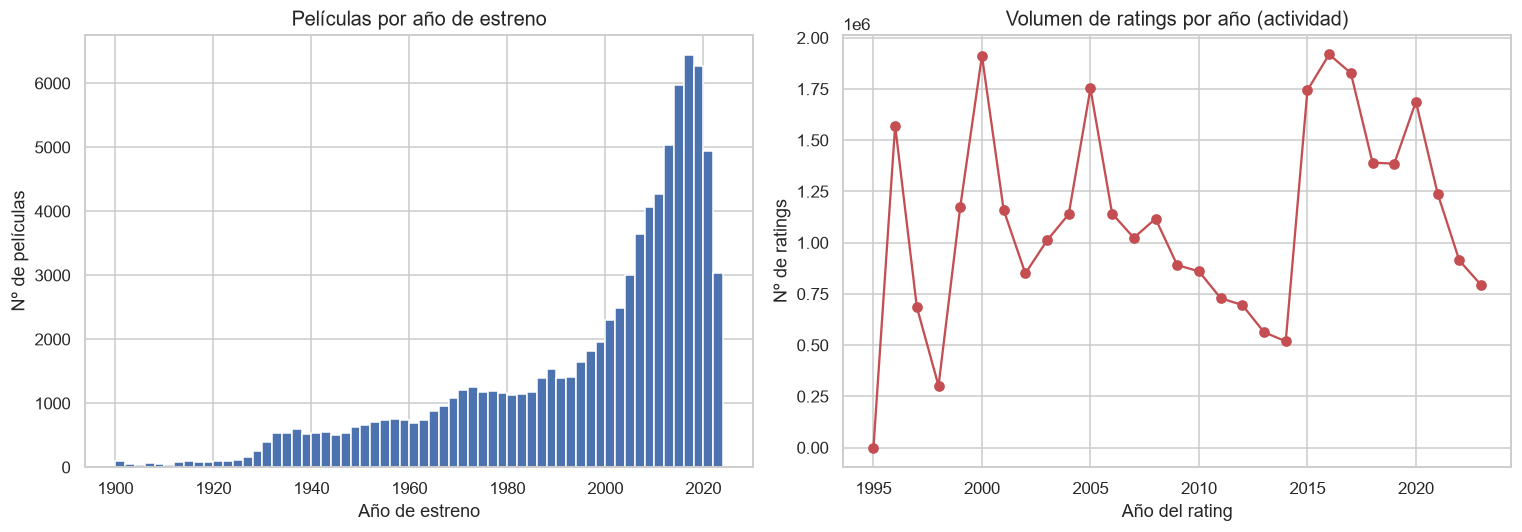

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Number of movies by release year.
year_counts = movies["year_movie"].dropna().astype(int)
year_counts = year_counts[(year_counts >= 1900) & (year_counts <= 2023)]
axes[0].hist(year_counts, bins=range(1900, 2025, 2), color="#4C72B0")
axes[0].set_title("Movies by release year")
axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Number of movies")

# (b) Rating volume by year submitted.
ratings_by_year = ratings.groupby("year").size()
axes[1].plot(ratings_by_year.index, ratings_by_year.values, marker="o", color="#C44E52")
axes[1].set_title("Rating volume per year (activity)")
axes[1].set_xlabel("Rating year"); axes[1].set_ylabel("Number of ratings")

plt.tight_layout(); plt.show()

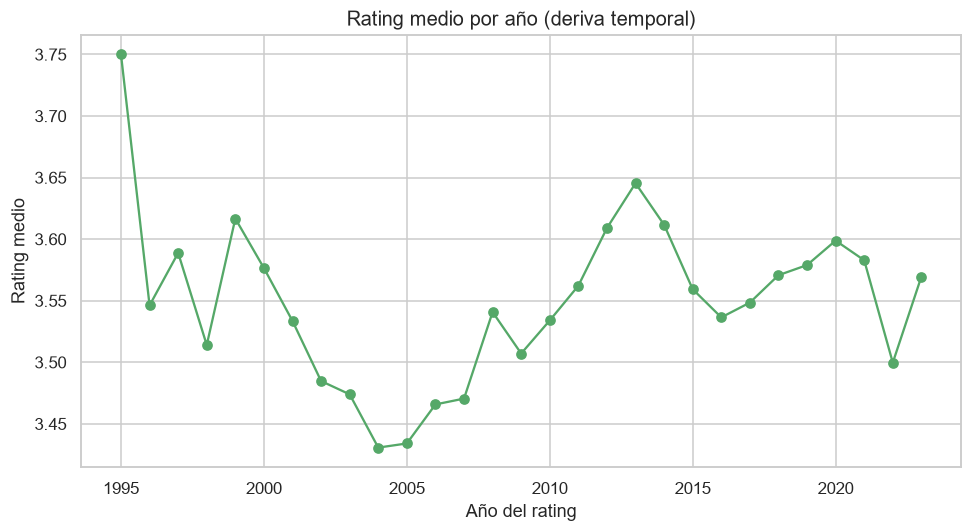

year
1995    3.750
1996    3.546
1997    3.589
1998    3.514
1999    3.617
2000    3.576
2001    3.534
2002    3.485
2003    3.474
2004    3.431
2005    3.434
2006    3.466
2007    3.470
2008    3.541
2009    3.507
2010    3.534
2011    3.562
2012    3.609
2013    3.645
2014    3.612
2015    3.559
2016    3.536
2017    3.548
2018    3.571
2019    3.579
2020    3.599
2021    3.583
2022    3.500
2023    3.570
Name: rating, dtype: float32

In [ ]:
# Does the average rating change over time?
mean_by_year = ratings.groupby("year")["rating"].mean()

fig, ax = plt.subplots()
ax.plot(mean_by_year.index, mean_by_year.values, marker="o", color="#55A868")
ax.set_title("Average rating per year (temporal drift)")
ax.set_xlabel("Rating year"); ax.set_ylabel("Average rating")
plt.tight_layout(); plt.show()

The catalog grows strongly from the 1990s onward and especially in the last two decades. Rating activity has peaks, and the average rating **is not constant** across years: there is a smooth temporal drift. This has a direct methodological consequence: a **temporal split** (train on the past, validate/test on the future) better reflects real-world deployment and avoids the optimism of mixing eras.

Ratings are skewed upward (mean ~3.5), activity follows a long tail across users and movies, and the matrix is >99.8% sparse. Drama/Comedy dominate the catalog and there is temporal drift in average ratings. All of this justifies using biased matrix factorization, filtering by minimum support, and temporal splitting.